# Analysis of AFM data

## Setup

### Install Gwyddion and export .spm files as .gwy

Install gwyddion: http://gwyddion.net/download.php#stable-sources 

(macOS needs an open source installer. Follow this guide: http://gwyddion.net/documentation/user-guide-en/installation-osx.html )


Then open each of your .spm files in Gwyddion.

Go to File -> Save as -> Add .gwy to the filename and make sure gwy-file format is selected.

Hint: ctrl + shift + s is the shortcut for save as.

When this is done, we have no more use for Gwyddion, and may close it (and uninstall, really).

### Make an environment for AFM data analysis, and install from .yml or .txt

Everyone should have this as a bookmark: https://docs.conda.io/projects/conda/en/latest/user-guide/tasks/manage-environments.html \
Open your prompt, and navigate to the folder where you have the .yml and .txt files.

Now Either:
1. Create a new environment and fill it with the .yml file directly:
    - conda env create -n TFY4330_AFM -f WallPY_minimal_requitements.yml

You may give it another name.
For pip, do the pip equivalent.

OR:
1. Create a new empty environment with conda (Again for pip, do the pip equivalent): 
    - conda env create --name your-awesome-enviroment-name 
2. Activate the environment: conda activate your-awesome-enviroment-name
3. Install using the following:
    - conda env update --file WallPY_minimal_requirements.yml --prune


To check if the environment is created, type conda env list. \
You should see a new environment in the list. \
Activate this environemnt by typing conda activate whatever-new-name-in-the-list. \
Check if the packages are installed by typing conda list


For PIP or if Murphys law:
1. Create a new environment
2. Activate the environment
3. Install python (3.8 or higher, but not too high)
5. Use pip to install gwyfile, matplotlib_scalebar, and h5py.
4. Install what remains of: matplotlib, numpy, pandas, scipy, scikit-learn, scikit-image, jupyter, ipykernel (conda or pip)
6. If you get requirement errors during the exercise, install the missing packages.

If you feel lucky:
1. Activate your previously created TFY4330 environment
2. pip install gwyfile
3. See if the code runs. If not, install the missing packages.
4. Hope there are no conflicts.


## Test

In [77]:
#TODO: Test dependencies by running this cell.

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import os
import sys

#NOTE: In case you do the analysis in another folder than the code, you need to provide the path to the code
wallpy_cmd = r"/Users/toham1999/Library/CloudStorage/OneDrive-NTNU/C 9.semester/Prosjekt/SPM" #NOTE: Path to the code
sys.path.append(os.path.join(wallpy_cmd, "Display"))
sys.path.append(os.path.join(wallpy_cmd, "IO"))
sys.path.append(os.path.join(wallpy_cmd, "Functionality"))
from figures import FigureSinglePlot, FigureSubplots
from universal_reader import GwyFile
import transformations as trans
import attributes as attr
import scipy as sp

%matplotlib inline
%reload_ext autoreload
%autoreload 2

In [78]:
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]

In [79]:
import shutil
print(shutil.which("latex"))

/Library/TeX/texbin/latex


## AFM analysis

### Create GwyFile objects

For each .gwy file you have, create a GwyFile object.\
The GwyFile object requires the _path_ and _filename_ of the .gwy file as input args

Hint: This repetitive task can be done in a loop, giving you a list of GwyFile objects. \
Hint: One can get all files in a folder by using the os.listdir() function, and one can filter the files by checking the file extension using str().endswith('your_desired_file_extension').

In [80]:
# TODO: Enter the path to the folder containing the .gwy files
gwy_folder = os.path.join("data", "2026-10-06_STO_Substrate", "gwy")

# TODO: Get all the correct files in the folder
gwy_files = sorted([f for f in os.listdir(gwy_folder) if f.lower().endswith(".gwy")])

# TODO: Create a list of GwyFile objects
gwy_objects = [GwyFile(gwy_folder, f) for f in gwy_files]

STO111_Substrate_0.gwy
H5 Structure exists.
Channels:
        ZSensor_None_0
        Voltage_None_1


STO111_Substrate_1.gwy
H5 Structure exists.
Channels:
        ZSensor_None_0
        Voltage_None_1


STO111_Substrate_3.gwy
H5 Structure exists.
Channels:
        ZSensor_None_0
        Voltage_None_1




### GwyFile Conversion

Run the '__call__()' method, which can be done simply by calling the object. I.e.: \
gwy = GwyFile(*args) \
gwy()

This will create a h5 file structure holding the AFM image as well as necessary metadata.
This can also be performed in a loop.

Do not mind error messages about keywords not found. Notice that some channels may have been lost. This is because the Bruker software does not include enough unique channel information in the name. If you want to keep both Trace and Retrace, add something to the channel name in the Gwyddion data Browser, like "Trace" and "Retrace",  \
Distinguishing the channel names in Gwyddion before conversion is also something one can do to separate height amplitude and phase from mfm amplitude and phase. 

In [81]:
# TODO: Call on the GwyFile objects.
for gwy in gwy_objects:
    gwy()

# TODO: When finished running this one, comment it out so that you do not spend time running it multiple times.


STO111_Substrate_0.gwy
Channels:
    ZSensor key not found in mode dictionary. Keys tried: ['Forward', 'Backward']
    ZSensor_None_0
    Peak Force Error key not found in mode dictionary. Keys tried: ['Forward', 'Backward']
    Voltage_None_1

STO111_Substrate_1.gwy
Channels:
    ZSensor key not found in mode dictionary. Keys tried: ['Forward', 'Backward']
    ZSensor_None_0
    Peak Force Error key not found in mode dictionary. Keys tried: ['Forward', 'Backward']
    Voltage_None_1

STO111_Substrate_3.gwy
Channels:
    ZSensor key not found in mode dictionary. Keys tried: ['Forward', 'Backward']
    ZSensor_None_0
    Peak Force Error key not found in mode dictionary. Keys tried: ['Forward', 'Backward']
    Voltage_None_1


### Get an overview of your data

We can plot all the channels with channel name and indices using the 'create_overview_file()' method.

If you do this in a loop, you can create overview .png files for each GwyFile object, and if you rememeber to use %matplotlib inline, you will get an overview of all the plots in the notebook.

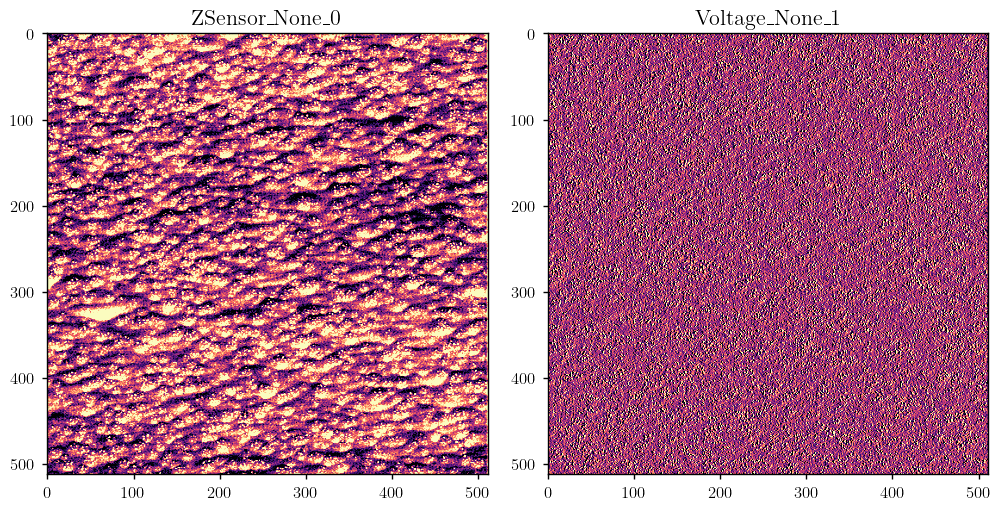

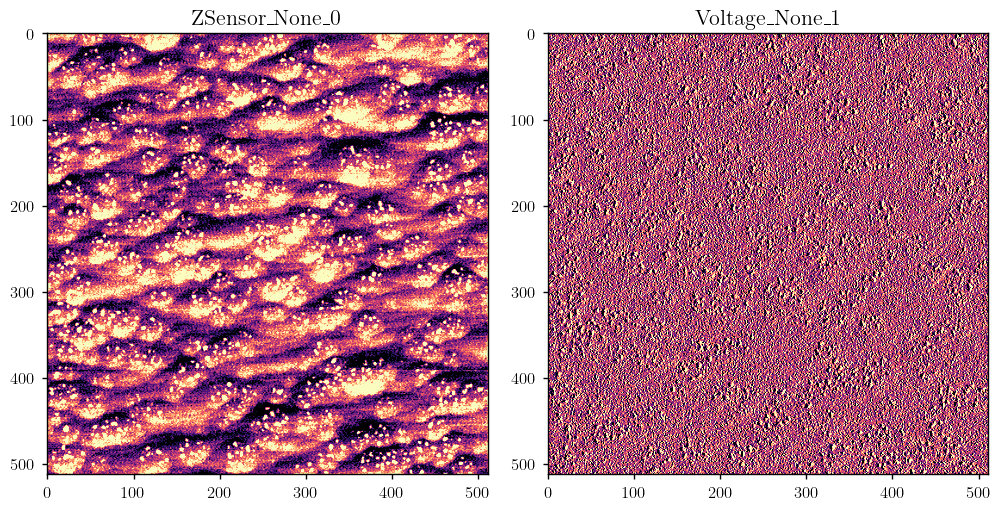

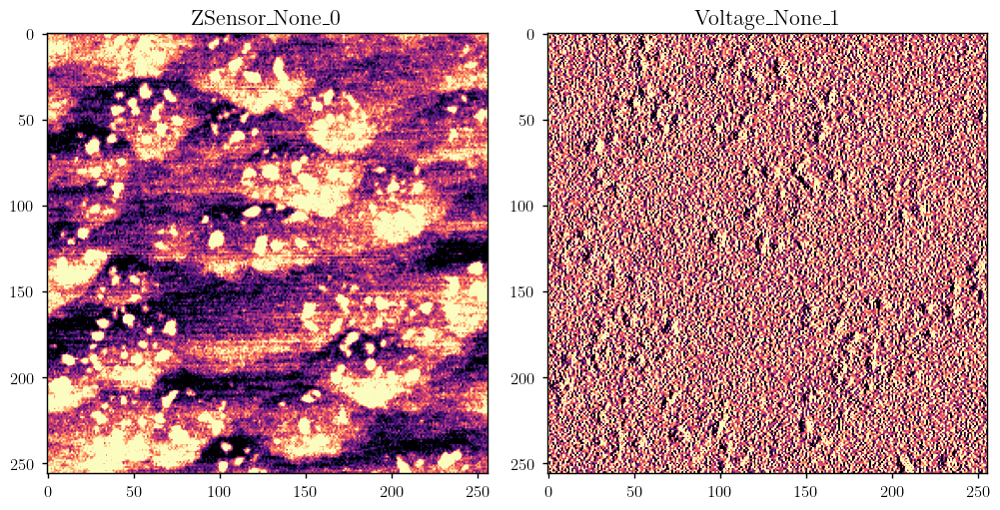

In [82]:
# TODO: Create an overview file/plot for each of the GwyFile objects.
for gwy in gwy_objects:
    gwy.create_overview_file()

### Choose files and channels of interest

Chose an overview scan and a close-up high resolution scan of the features of interest. \
These you may extract from the list, e.g. by indexing. \
NB! Make sure you know what you extract. The instrument mixes and matches channels, and you may not get what you expect. \
Generally, the MFM should not correlate perfectly with the topography, and have worse spatial resolution. \
Optional, by opening the .spm file in a text editor, you can confirm that the phase and amplitude channels indeed are MFM channels by the "Scan Line: Interleave" keyword for the given "Image Data" keyword.

Extracting channels is most easily done by indexing the desired channel, gwyfile[channel_index], where channel_index is the number at the end of the channel title in the overview plot. \
For more on indexing, visit the source code. 


In [83]:
#TODO: Extract GwyFile objects of interest, as well as the corresponding channels of interest.
selected_channels = {
    "STO111_Substrate_0.gwy": ["ZSensor_None_0", "Voltage_1"],
    "STO111_Substrate_1.gwy": ["ZSensor_None_0", "Voltage_1"],
    "STO111_Substrate_3.gwy": ["ZSensor_None_0", "Voltage_1"]
}
selected_data = {
    filename: {channel: gwy[channel] for channel in channels}
    for filename, channels in selected_channels.items()
    for gwy in gwy_objects
    if f"{gwy.filename}.gwy" == filename
}

### Plot and Analysing the topography
Plot the raw height data, the topography amplitude signal, and the three processed height arrays side by side using plt.subplots() and imshow(). Do this for both the overview and the high resolution image. You can decide if you want to make two figures or one figure with two rows. In the latter case, you will get a 2D array of axes objects.
You can iterate over axs.shape[1], and call axs[0][i].imshow() and axs[1][i].imshow(), respectively, for overview and hr image.

Make it pretty by:
- cropping if necessary 
- adding scalebars
- choosing colormaps for the different signals
- adjusting vmin and vmax by using np.quantile(arr, q)
- adding letters and labels. 
- Decide on whether to use colorbars or not.

Hint: 
In attributes.py, imported as attr, you can find an implementation of a scalebar function, as well as subplot labelling function.\
attr.add_scalebar(ax, res)\
attr.add_letter(ax, letter), where letter can be chr(97) + n to quickly get a, b, c, d etc. \
OR, use the functions used in previous exercises. \
To get the resolution of the image, use gwy_file_obj.index_metadata(index, "xres")

In [84]:
from scripts.plot_spm_folder import add_cbar, add_scalebar, params

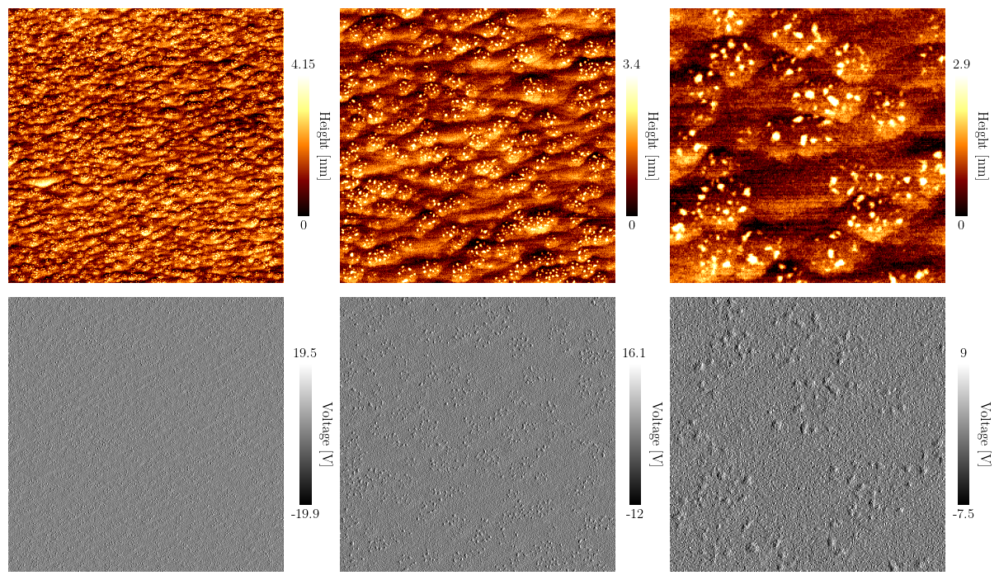

In [85]:
fig, axs = plt.subplots(2, len(selected_data), figsize=(12, 7), squeeze=False)

for col, (filename, channels) in enumerate(selected_data.items()):
    for row, (channel, data) in enumerate(channels.items()):
        channel_type = channel.split("_")[0]
        settings = params[channel_type]
        data = data * settings["datascale"]

        im = axs[row, col].imshow(data,cmap=settings["cmap"],vmin=np.quantile(data, 0.01),vmax=np.quantile(data, 0.99))

        axs[row, col].axis("off")
        add_cbar(im, axs[row, col], data, settings["label"])

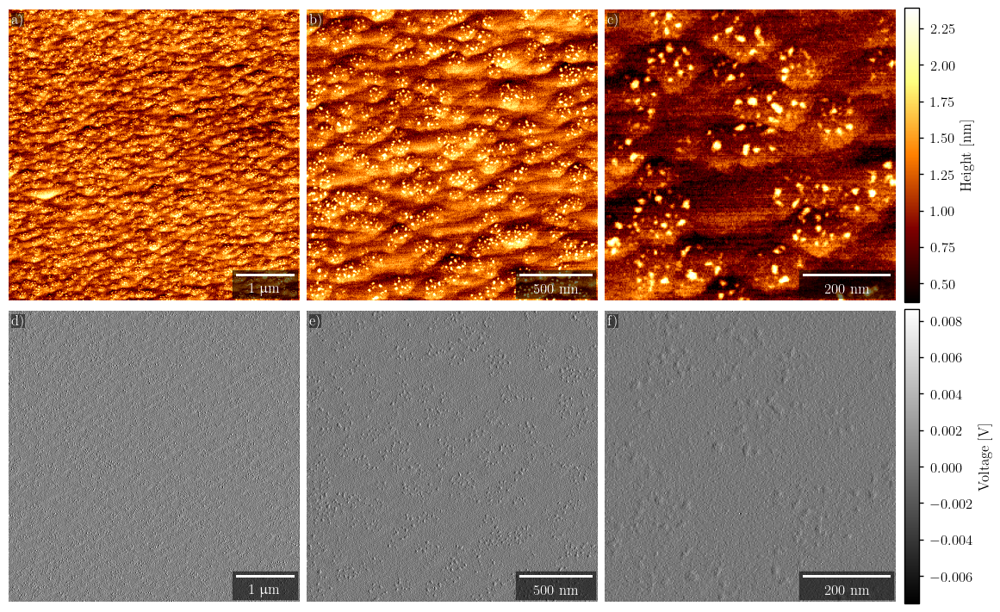

In [92]:
# Create figure and axis array
fig, axs = plt.subplots(2, len(selected_data), figsize=(11.5, 7), squeeze=False)

# Calculate common color limits for ZSensor
zsensor_data = [channels["ZSensor_None_0"] * 1e9 for channels in selected_data.values()]
zsensor_vmin = min(np.quantile(data, 0.01) for data in zsensor_data)
zsensor_vmax = max(np.quantile(data, 0.99) for data in zsensor_data)

# Calculate common color limits for Voltage
voltage_data = [channels["Voltage_1"] for channels in selected_data.values()]
voltage_vmin = min(np.quantile(data, 0.01) for data in voltage_data)
voltage_vmax = max(np.quantile(data, 0.99) for data in voltage_data)

# Plot images
for col, (filename, channels) in enumerate(selected_data.items()):
    sd = channels["ZSensor_None_0"] * 1e9
    axs[0, col].imshow(sd, cmap=params["ZSensor"]["cmap"], vmin=zsensor_vmin, vmax=zsensor_vmax)
    sd = channels["Voltage_1"]
    axs[1, col].imshow(sd, cmap=params["Voltage"]["cmap"], vmin=voltage_vmin, vmax=voltage_vmax)

# Title list
title_list = ["ZSensor", "Voltage"]

# Add scale bars and labels
for col, (filename, channels) in enumerate(selected_data.items()):
    for row, channel in enumerate(["ZSensor_None_0", "Voltage_1"]):
        ax = axs[row, col]
        ax.axis("off")
        gwy = next(gwy for gwy in gwy_objects if f"{gwy.filename}.gwy" == filename)
        attr.add_scalebar(ax, res=gwy.index_metadata(channel, "xres"))
        attr.add_alphabetic_label(ax, chr(97 + row * len(selected_data) + col) + ")", position=(0.01, 0.99), font_properties=26, verticalalignment="top")

# Add one colorbar for each row
fig.colorbar(axs[0, 0].images[0], ax=axs[0, :], orientation="vertical", fraction=0.046, pad=0.01, label="Height [nm]")
fig.colorbar(axs[1, 0].images[0], ax=axs[1, :], orientation="vertical", fraction=0.046, pad=0.01, label="Voltage [V]")

plt.show()

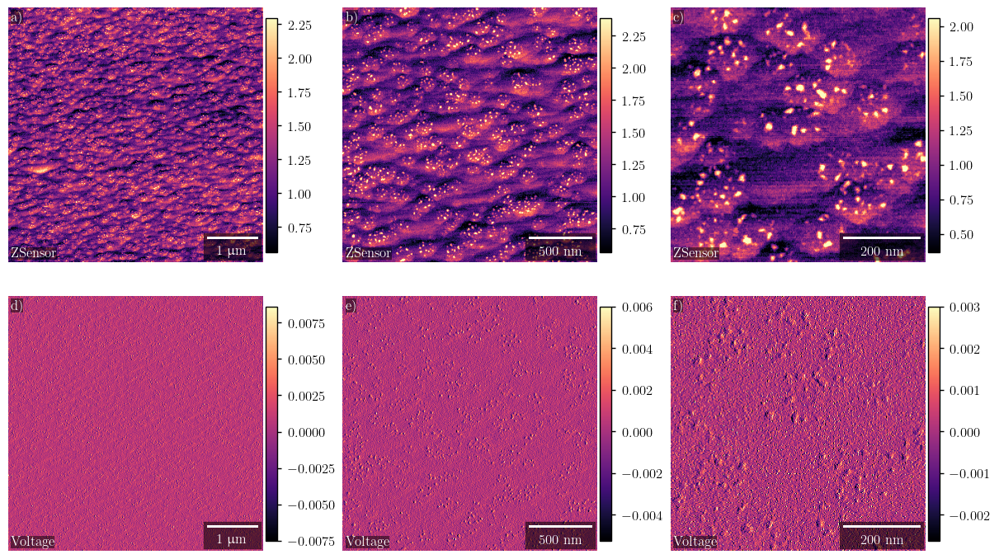

In [87]:
# Create figure and axis array
fig, axs = plt.subplots(2, len(selected_data), figsize=(12, 7))

# Plot images
for col, (filename, channels) in enumerate(selected_data.items()):
    sd = channels["ZSensor_None_0"] * 1e9 # Convert to nanometers
    axs[0, col].imshow(sd, vmin=np.quantile(sd, 0.01), vmax=np.quantile(sd, 0.99))

    sd = channels["Voltage_1"]
    axs[1, col].imshow(sd, vmin=np.quantile(sd, 0.01), vmax=np.quantile(sd, 0.99))

# Title list
title_list = ["ZSensor", "Voltage"]

# Add scale bars and labels
for col, (filename, channels) in enumerate(selected_data.items()):
    for row, channel in enumerate(["ZSensor_None_0", "Voltage_1"]):
        ax = axs[row, col]
        ax.axis("off")

        gwy = next(gwy for gwy in gwy_objects if f"{gwy.filename}.gwy" == filename)
        attr.add_scalebar(ax, res=gwy.index_metadata(channel, "xres"))

        attr.add_alphabetic_label(ax, chr(97 + row * len(selected_data) + col) + ")", position=(0.01, 0.99))
        attr.add_alphabetic_label(ax, title_list[row], position=(0.01, 0.01), verticalalignment="bottom")
        attr.add_colorbar(ax, ax.images[0], orientation="vertical", fraction=0.046, pad=0.01)

plt.show()

### Drawing crossections

1D crossections are often useful and necessary to properly analyze and present AFM data. \
Make two crossections from the high-resolution data. \
You can either do vertical/horizontal crossections, or utilize the functions in crossectioning.py to draw arbitrary crossections. \
For the latter, the points may be chosen interactively by switching to %matplotlib qt, plotting a helping figure, calling the retrieve_crossection_coordinates() function, reading the coordinates, and retrieving the crossection using the retrieve_crossection() function. Alternatively, coordinates may be entered directly into the last function.

In either case, choose an appropiate line width to average over to get an acceptable signal to noise ratio. Here, slicing and arr.mean(axis: int) may be useful.




In [88]:
#TODO: Draw crossections from the high resolution data



### Plotting a figure with crossections

For this figure, you will be using gridspec one way or another. \
You can either code using gridspec, or you can try FigureSubplots from figures.py. \
This class is an overhead class that simplifies the use of gridspec. \

The figure should fulfill the following requirements:
- The figure should be 3x3 in terms of grid cells (nrows=3, ncols=3 for FigureSubplots)
- 1 out of 3 column widths should be used for the 2D image of the channel.
- 2 out of 3 column widths should be used for the crossections.
- The position of the crossection should be indicated on the 2D image.

Hint: Read the FigureSubplots docstring. It is unfortunately not very readable due to many **kwargs. \
Essentially, create the fig by initiated a class instance. \
For each subplot, call create_subplot( row:int, col:int, rowspan:int, colspan:int) with the desired parameters. Note that the span is the end index for some reason... \
This will return Ax objects, not axis objects. This is an overhead class, and you may access the actual axis object by writing Ax.ax. \
Labelling can be done using the label_subplot() method. \
Finally, call the figure object to save. 

In [89]:
#TODO: Create a figure with subplots using FigureSubplots or Gridspec directly.
#TODO: Plot the 2D data and the crossections in the same figure.
#TODO: Add all the fuzz.

### Plotting in 3D with phase coloring

MFM gives quantitative (x,y,z)-information as well as qualitative information about the magnetic properties of the sample. \
This can be visualized in a single plot by plotting the height data in 3D with surface coloring representing the MFM phase. \
Often these types of plots do not convey that much information, but they are satisfying and cool, and one should therefore learn to make them. 

Use the fig = plt.figure() and ax = fig.add_subplot(111, projection='3d') to make a 3D plot. \
Use ax.plot_surface() to plot the high resolution height data, and use the c argument to color the surface by the MFM phase. \
By using mpl.colors.Normalize() and cm.ScalarMappable() you can create a colorbar for the phase.

Finally, make everything pretty.

In [90]:
#TODO: Create figure and ax with 3D projection
#TODO: Make the x, and y axes in by np.arange and np.meshrgrid to map out all coordinates, and transform to physical units.
#TODO: Choose a cmap from mpl.cm.'colormap_name', and normalize the color range using mpl.colors.Normalize(vmin=, vmax=). This gives a norm object.
#TODO: Normalize the phase data by passing it as an argument to the norm object. This gives a color array.
#TODO: Plot the surface using ax.plot_surface(). Provide the X, Y, Z and facecolors arguments.
#TODO: Do all the pretty fuzz, like labels, limits, remove grid, make transparent, etc.